<a href="https://colab.research.google.com/github/maureljean55/atelier-saint-honore/blob/main/notebooks/q5_knn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

clients = pd.read_csv("sample_data/client_propre.csv")
print("clients :", clients.shape)

clients : (679, 13)


In [5]:
clients.head()

,client_id,boutique_principale,anciennete_mois,nb_achats_12m,panier_moyen_eur,retours,demandes_sav,carte_fidelite,canal_prefere,pays_residence,montant_prochain_achat_eur,est_revenu_6m,montant_total_eur
0,CT80059,BT15,4,4,1468.0,0,0,aucune,en ligne,usa,725.0,1,5872.0
1,CT80578,BT28,80,3,1235.0,1,1,argent,boutique,france,1479.0,1,3705.0
2,CT80256,BT27,43,1,1814.0,0,2,or,boutique,france,2307.0,1,1814.0
3,CT80098,BT16,1,1,1795.0,0,0,or,boutique,italie,1820.0,0,1795.0
4,CT80362,BT31,51,3,2022.0,0,0,argent,boutique,chine,1201.0,1,6066.0


In [6]:
clients["est_revenu_6m"].value_counts()

,count
est_revenu_6m,
0,401
1,278


In [7]:
part_partis = (clients["est_revenu_6m"] == 0).mean() * 100
part_revenus = (clients["est_revenu_6m"] == 1).mean() * 100

print("Clients qui ne reviennent pas :", round(part_partis, 1), "%")
print("Clients qui reviennent :", round(part_revenus, 1), "%")

Clients qui ne reviennent pas : 59.1 %
Clients qui reviennent : 40.9 %


### Choix des colonnes

In [8]:
cols = ["anciennete_mois", "nb_achats_12m", "panier_moyen_eur", "montant_total_eur", "retours", "demandes_sav"]

clients.groupby("est_revenu_6m")[cols].mean().round(2)

,anciennete_mois,nb_achats_12m,panier_moyen_eur,montant_total_eur,retours,demandes_sav
est_revenu_6m,,,,,,
0,28.50,3.15,2437.84,9689.42,0.49,0.4
1,34.27,4.39,2938.97,16916.82,0.48,0.4


In [9]:
clients.groupby("est_revenu_6m")[cols].median().round(1)

,anciennete_mois,nb_achats_12m,panier_moyen_eur,montant_total_eur,retours,demandes_sav
est_revenu_6m,,,,,,
0,22.0,2.0,2046.0,4586.0,0.0,0.0
1,26.0,3.0,2224.0,6297.0,0.0,0.0


In [10]:
cols_utiles = ["anciennete_mois", "nb_achats_12m", "panier_moyen_eur", "montant_total_eur"]
clients[cols_utiles].corr().round(2)

,anciennete_mois,nb_achats_12m,panier_moyen_eur,montant_total_eur
anciennete_mois,1.00,-0.05,-0.32,-0.21
nb_achats_12m,-0.05,1.00,0.54,0.84
panier_moyen_eur,-0.32,0.54,1.00,0.85
montant_total_eur,-0.21,0.84,0.85,1.00


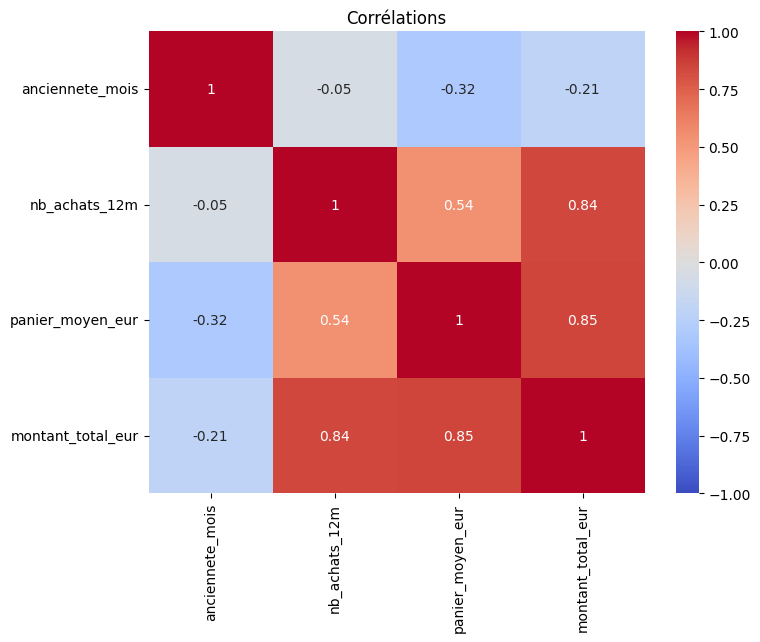

In [23]:
matrice = clients[cols_utiles].corr().round(2)

plt.figure(figsize=(8, 6))
sns.heatmap(matrice, annot=True, cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Corrélations")
plt.show()

In [12]:
X = clients[["anciennete_mois", "nb_achats_12m"]]
y = (clients["est_revenu_6m"] == 0)

X.head()

,anciennete_mois,nb_achats_12m
0,4,4
1,80,3
2,43,1
3,1,1
4,51,3


In [13]:
X.agg(["min", "max", "mean", "std"]).round(2)

,anciennete_mois,nb_achats_12m
min,1.00,1.00
max,116.00,17.00
mean,30.86,3.66
std,24.39,2.92


### Standardisation et choix de k

In [14]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(5, shuffle=True, random_state=42)

score_brut = cross_val_score(KNeighborsClassifier(21), X, y, cv=cv)
modele_std = make_pipeline(StandardScaler(), KNeighborsClassifier(21))
score_std = cross_val_score(modele_std, X, y, cv=cv)

print("Sans standardiser :", round(score_brut.mean(), 3))
print("Avec standardisation :", round(score_std.mean(), 3))

Sans standardiser : 0.583
Avec standardisation : 0.629


In [15]:
valeurs_k = [1, 3, 5, 7, 11, 15, 21, 31, 51]
resultats = []

for k in valeurs_k:
    modele = make_pipeline(StandardScaler(), KNeighborsClassifier(k))
    scores = cross_val_score(modele, X, y, cv=cv)
    resultats.append({
        "k": k,
        "justesse": round(scores.mean(), 3),
        "ecart_type": round(scores.std(), 3)
    })

resultats_k = pd.DataFrame(resultats)
resultats_k

,k,justesse,ecart_type
0,1,0.530,0.030
1,3,0.574,0.027
2,5,0.573,0.024
3,7,0.598,0.033
4,11,0.611,0.038
5,15,0.611,0.022
6,21,0.629,0.031
7,31,0.611,0.029
8,51,0.613,0.041


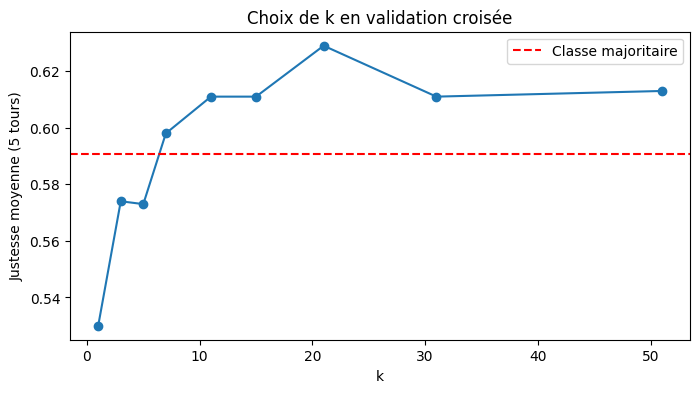

In [16]:
plt.figure(figsize=(8, 4))
plt.plot(resultats_k["k"], resultats_k["justesse"], marker="o")
plt.axhline(y.mean(), color="red", linestyle="--", label="Classe majoritaire")
plt.xlabel("k")
plt.ylabel("Justesse moyenne (5 tours)")
plt.title("Choix de k en validation croisée")
plt.legend()
plt.show()

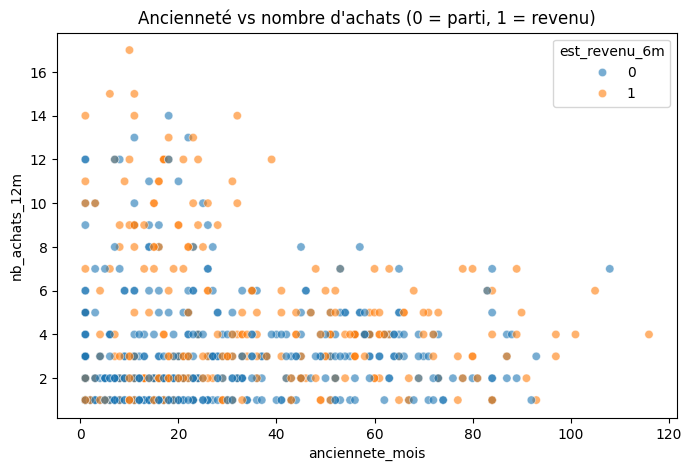

In [17]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=clients, x="anciennete_mois", y="nb_achats_12m", hue="est_revenu_6m", alpha=0.6)
plt.title("Ancienneté vs nombre d'achats (0 = parti, 1 = revenu)")
plt.show()

### Test du modèle et prédictions

In [18]:
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()
X_tr_std = scaler.fit_transform(X_tr)
X_te_std = scaler.transform(X_te)

knn = KNeighborsClassifier(21).fit(X_tr_std, y_tr)
pred = knn.predict(X_te_std)

print("Exactitude :", round((pred == y_te).mean(), 3))
print("Vrais départs détectés :", (pred & y_te).sum(), "sur", y_te.sum())
print("Clients fidèles appelés pour rien :", (pred & (~y_te)).sum(), "sur", (~y_te).sum())

Exactitude : 0.588
Vrais départs détectés : 86 sur 120
Clients fidèles appelés pour rien : 50 sur 84


In [19]:
pd.crosstab(y_te, pred, rownames=["Réel (parti)"], colnames=["Prédit (parti)"])

Prédit (parti),False,True
Réel (parti),,
False,34,50
True,34,86


In [20]:
modele_final = make_pipeline(StandardScaler(), KNeighborsClassifier(21)).fit(X, y)

exemples = pd.DataFrame([
    [3, 1],
    [36, 4],
    [72, 10]
], columns=["anciennete_mois", "nb_achats_12m"])

exemples["va_partir"] = modele_final.predict(exemples)
exemples["proba_depart"] = modele_final.predict_proba(exemples[["anciennete_mois", "nb_achats_12m"]])[:, 1].round(2)
exemples["voisins_sur_21"] = (exemples["proba_depart"] * 21).round(0).astype(int)

exemples

,anciennete_mois,nb_achats_12m,va_partir,proba_depart,voisins_sur_21
0,3,1,True,0.86,18
1,36,4,False,0.48,10
2,72,10,False,0.29,6


In [21]:
clients["proba_depart"] = modele_final.predict_proba(X)[:, 1].round(2)

clients[["client_id", "boutique_principale", "anciennete_mois", "nb_achats_12m", "panier_moyen_eur", "proba_depart"]].sort_values("proba_depart", ascending=False).head(10)

,client_id,boutique_principale,anciennete_mois,nb_achats_12m,panier_moyen_eur,proba_depart
3,CT80098,BT16,1,1,1795.0,0.86
10,CT80695,BT13,22,5,1879.0,0.86
491,CT80406,BT10,1,2,1444.0,0.86
37,CT80422,BT29,3,2,1971.0,0.86
310,CT80170,BT10,22,5,3905.0,0.86
49,CT80606,BT10,3,2,2665.0,0.86
270,CT80038,BT28,3,1,2479.0,0.86
63,CT80608,BT12,1,1,3418.0,0.86
46,CT80618,BT10,1,1,1665.0,0.86
440,CT80303,BT14,2,1,1817.0,0.86
